In [12]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
import pandas as pd
from pathlib import Path
from PIL import Image


In [13]:
DATA_DIR = Path("../data/")
OUT_DIR = (DATA_DIR / "processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)
Size=(224,224)

def load_resized(path, size = Size):
    with Image.open(path) as img:
        return np.asarray(img.convert("L").resize(size), dtype=np.uint8)


def build_split(csv_name, out_name):
    df = pd.read_csv(DATA_DIR/csv_name)
    X = np.stack([load_resized(p, (64,64)) for p in df["Path"]])
    y = df["Labels"].to_numpy()
    np.savez_compressed(OUT_DIR / out_name, X=X, y=y)
    print(out_name, X.shape, X.dtype)



build_split("train.csv", "train_64.npz")
build_split("test.csv", "test_64.npz")
build_split("val.csv", "val_64.npz")


train_64.npz (4728, 64, 64) uint8
test_64.npz (1584, 64, 64) uint8
val_64.npz (701, 64, 64) uint8


In [14]:
DATA_DIR = Path("../data/")
OUT_DIR = (DATA_DIR / "processed")

def load_split(name):
    data = np.load(OUT_DIR / f"{name}.npz", allow_pickle=True)
    return normalize(data["X"]), data["y"]
def normalize(X):
    X = X.astype(np.float32)
    mins = X.min(axis=(1,2), keepdims=True)
    maxs = X.max(axis=(1,2), keepdims=True)
    return (X - mins) / (maxs - mins + 1e-8)

x_train, y_train = load_split("train_64")
x_val, y_val = load_split("val_64")
x_test, y_test = load_split("test_64")

In [27]:
UN_DT = DecisionTreeClassifier(
    random_state=42,
)
x_train = x_train.reshape(x_train.shape[0], -1)
x_val = x_val.reshape(x_val.shape[0], -1)
x_test = x_test.reshape(x_test.shape[0], -1)

UN_DT.fit(x_train, y_train)
print(classification_report(y_train, UN_DT.predict(x_train)))
print(classification_report(y_val, UN_DT.predict(x_val)))

              precision    recall  f1-score   support

      glioma       1.00      1.00      1.00      1219
  meningioma       1.00      1.00      1.00      1207
     notumor       1.00      1.00      1.00      1116
   pituitary       1.00      1.00      1.00      1186

    accuracy                           1.00      4728
   macro avg       1.00      1.00      1.00      4728
weighted avg       1.00      1.00      1.00      4728

              precision    recall  f1-score   support

      glioma       0.86      0.82      0.84       181
  meningioma       0.73      0.70      0.71       179
     notumor       0.89      0.91      0.90       165
   pituitary       0.85      0.90      0.87       176

    accuracy                           0.83       701
   macro avg       0.83      0.83      0.83       701
weighted avg       0.83      0.83      0.83       701



In [28]:
UN_DT.get_depth() # get the max depth

22

### Tuning

In [22]:
from sklearn.metrics import f1_score

depths = [5, 8, 10, 12, 15, 18, None]
leaf_sizes = [1, 2, 5, 10]

results = []

for depth in depths:
    for leaf in leaf_sizes:
        tree = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=42,
        )
        tree.fit(x_train, y_train)

        train_f1 = f1_score(y_train, tree.predict(x_train), average="macro")
        val_f1 = f1_score(y_val, tree.predict(x_val), average="macro")

        results.append({
            "max_depth": depth,
            "min_samples_leaf": leaf,
            "train_f1": round(train_f1, 3),
            "val_f1": round(val_f1, 3),
            "gap": round(train_f1 - val_f1, 3),
        })
results_df = pd.DataFrame(results).sort_values("val_f1", ascending=False)
results_df


,max_depth,min_samples_leaf,train_f1,val_f1,gap
16,15.0,1,0.995,0.850,0.145
21,18.0,2,0.986,0.850,0.136
26,NaN,5,0.957,0.846,0.111
22,18.0,5,0.957,0.846,0.111
25,NaN,2,0.986,0.845,0.142
12,12.0,1,0.986,0.844,0.142
18,15.0,5,0.957,0.843,0.114
10,10.0,5,0.944,0.842,0.102
13,12.0,2,0.977,0.842,0.135
14,12.0,5,0.955,0.842,0.113


In [23]:
DT = DecisionTreeClassifier(max_depth=10, min_samples_leaf=5, random_state=42)
DT.fit(x_train, y_train)
print(classification_report(y_val, DT.predict(x_val)))
print(classification_report(y_test, DT.predict(x_test)))

              precision    recall  f1-score   support

      glioma       0.89      0.80      0.84       181
  meningioma       0.73      0.74      0.73       179
     notumor       0.90      0.91      0.91       165
   pituitary       0.85      0.91      0.88       176

    accuracy                           0.84       701
   macro avg       0.84      0.84      0.84       701
weighted avg       0.84      0.84      0.84       701

              precision    recall  f1-score   support

      glioma       0.85      0.59      0.70       386
  meningioma       0.67      0.72      0.69       398
     notumor       0.76      0.95      0.84       400
   pituitary       0.86      0.83      0.84       400

    accuracy                           0.77      1584
   macro avg       0.78      0.77      0.77      1584
weighted avg       0.78      0.77      0.77      1584



### Confusion Matrix

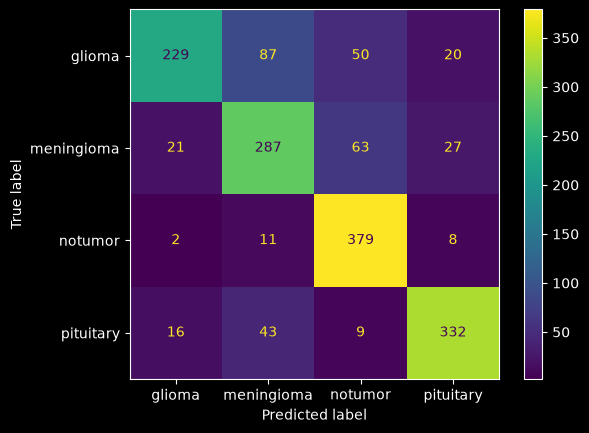

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print(ConfusionMatrixDisplay.from_predictions(y_test, DT.predict(x_test)))